In [43]:
# Instale através do requirements.txt: pip install -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as skl
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Input, Dropout, BatchNormalization
from keras.callbacks import EarlyStopping
from keras import regularizers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Obtendo o dataset
df = pd.read_csv("../data/base_classificacao_binaria.csv")

# Etapa 1: Entendimento do Problema

### Tipo de problema
O desenvolvimento do projeto toma como base o dataset ```base_classificacao_binaria.csv``` (recorte do dataset abaixo) e se fundamenta no aprendizado supervisionado, dado que cada amostra possui seu respectivo rótulo de saída (```target```). Além disso, se trata de um problema de classificação, em que o modelo deve identificar os padrões nos atributos de entrada para determinar a qual classe discreta (binária, neste caso) a amostragem pertence.

### Features e Labels
O dataset já nos dá um norte bem forte sobre quais métricas escolher como ```features``` e qual escolher como ```label```. No nosso dataset temos um total de 13 colunas, sendo 11 delas numéricas, 1 de índice de 1 de dados em string. A última coluna é uma coluna de valores binários chamada de ```target```, e é justamente o que queremos prever com base nos dados das colunas anteriores. 

Sabendo disso, iremos adotar as seguintes _features_:
```sensor_a```, ```sensor_b```, ```sensor_c```, ```measurement_d```, ```measurement_e```, ```measurement_f```, ```measurement_g```, ```measurement_h```, ```measurement_j```, ```ratio_j``` e ```environment```.
Nosso _label_ será a coluna ```target```.



In [34]:
# Data sample
df.head()
#df.describe()

,sample_id,sensor_a,sensor_b,sensor_c,measurement_d,measurement_e,measurement_f,measurement_g,measurement_h,measurement_i,ratio_j,environment,target,encoded_environment
0,S08268,8.914515,867.306001,0.019069,NaN,45.686368,1.700616,-0.902463,NaN,0.453651,1.017578,hot,0,2.0
1,S03978,6.648553,1092.307380,0.029332,NaN,53.110799,-0.208217,-2.485422,-1.579362,0.971668,3.516217,hot,0,2.0
2,S03450,10.803832,952.510306,0.055172,0.644110,50.427537,2.361744,NaN,-0.285890,0.326307,1.623479,hot,1,2.0
3,S00187,8.140751,669.676350,0.063204,1.174591,55.814057,0.740185,-2.444912,-1.822998,NaN,0.733792,mild,1,1.0
4,S02910,8.351185,1302.375048,0.046524,0.674800,55.144315,0.530997,-0.405251,NaN,-0.755999,0.716739,cold,0,0.0


# Etapa 2: Análise Exploratória de Dados

Nesta etapa, será realizado um diagnóstico para verificar a qualidade e a integridade dos dados do dataset. Faremos isso por meio de análises gráficas e quantitativas dos dados através das bibliotecas ```pandas``` e ```matplotlib```, se aproveitando de histogramas (para verificar a distribuição), _box-plots_ (para verificar a existência de _outliers_), ferramentas para identificar inconsistências (valores nulos ou repetidos) e plotar uma matriz de correlação que vai nos dizer quais métricas possuem correlação forte/fraca.

## Etapa 2.1: Análise de distribuição dos dados através de histogramas
Nesta etapa, será realizada uma análise da distribuição dos dados utilizando histogramas. As informações que os histogramas nos dão são valiosas, uma vez que a partir dele conseguimos detectar discrepâncias entre as medidas de cada coluna e se elas seguem uma distribuição normal (importante para as etapas de imputação e escalonamento dos dados). 

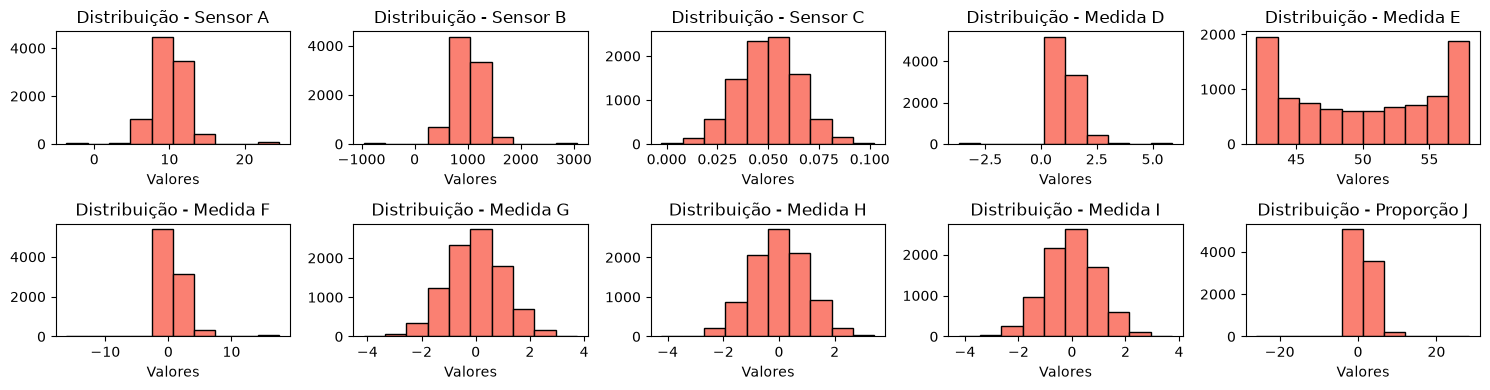

In [4]:
# Histogramas

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(15, 4))

axes[0][0].hist(df["sensor_a"], color="salmon", edgecolor="black")
axes[0][0].set_title("Distribuição - Sensor A")
axes[0][0].set_xlabel("Valores")

axes[0][1].hist(df["sensor_b"], color="salmon", edgecolor="black")
axes[0][1].set_title("Distribuição - Sensor B")
axes[0][1].set_xlabel("Valores")

axes[0][2].hist(df["sensor_c"], color="salmon", edgecolor="black")
axes[0][2].set_title("Distribuição - Sensor C")
axes[0][2].set_xlabel("Valores")

axes[0][3].hist(df["measurement_d"], color="salmon", edgecolor="black")
axes[0][3].set_title("Distribuição - Medida D")
axes[0][3].set_xlabel("Valores")

axes[0][4].hist(df["measurement_e"], color="salmon", edgecolor="black")
axes[0][4].set_title("Distribuição - Medida E")
axes[0][4].set_xlabel("Valores")

axes[1][0].hist(df["measurement_f"], color="salmon", edgecolor="black")
axes[1][0].set_title("Distribuição - Medida F")
axes[1][0].set_xlabel("Valores")

axes[1][1].hist(df["measurement_g"], color="salmon", edgecolor="black")
axes[1][1].set_title("Distribuição - Medida G")
axes[1][1].set_xlabel("Valores")

axes[1][2].hist(df["measurement_h"], color="salmon", edgecolor="black")
axes[1][2].set_title("Distribuição - Medida H")
axes[1][2].set_xlabel("Valores")

axes[1][3].hist(df["measurement_i"], color="salmon", edgecolor="black")
axes[1][3].set_title("Distribuição - Medida I")
axes[1][3].set_xlabel("Valores")

axes[1][4].hist(df["ratio_j"], color="salmon", edgecolor="black")
axes[1][4].set_title("Distribuição - Proporção J")
axes[1][4].set_xlabel("Valores")

plt.tight_layout()
plt.show()

## Interpretação dos gráficos

- **Distribuições normais (Gaussianas)**: As variáveis ``sensor_c``, ``measurement_g``, ``measurement_h`` e ``measurement_i`` apresentam o formato clássico de "sino", com os dados concentrados em torno da média. Para essas variáveis, imputar valores nulos usando a média é uma boa estratégia (Etapa 3), e elas responderão muito bem ao StandardScaler (Etapa 4).

- **Distribuições Asssimétricas**: O ``sensor_a``, ``sensor_b``, ``measurement_d``, ``measurement_f`` e ``ratio_j`` possuem picos acentuados e caudas longas (assimetria). O uso da mediana pode ser mais seguro para a imputação de nulos nessas colunas (Etapa 3).

- **Distribuição Bimodal**: A ``measurement_e`` foge completamente do padrão das outras medidas e apresenta uma distribuição bimodal com picos nas pontas. Essa variável não possui uma tendência central clara.

## Etapa 2.2: Análise de _outliers_ através de boxplots.

Os boxplots em subgráficos individuais permitem visualizar discrepâncias que não eram óbvias no gráfico unificado.

## Interpretação dos gráficos:

- **Presença de Outliers**: Com exceção da ``measurement_e`` (que não apresenta pontos fora dos limites dos "bigodes"), todas as outras variáveis possuem outliers significativos em ambas as direções (valores extremos muito altos e muito baixos).

- **Impacto no Escalonamento**: A presença severa de outliers no ``sensor_b``, ``measurement_f`` e ``ratio_j`` sugere que essas variáveis podem distorcer o cálculo da média e da variância. O escalonamento padrão (``StandardScaler``) será afetado, pois ele é sensível a extremos.

sensor_a            Axes(0.125,0.53;0.133621x0.35)
sensor_b         Axes(0.285345,0.53;0.133621x0.35)
sensor_c          Axes(0.44569,0.53;0.133621x0.35)
measurement_d    Axes(0.606034,0.53;0.133621x0.35)
measurement_e    Axes(0.766379,0.53;0.133621x0.35)
measurement_f       Axes(0.125,0.11;0.133621x0.35)
measurement_g    Axes(0.285345,0.11;0.133621x0.35)
measurement_h     Axes(0.44569,0.11;0.133621x0.35)
measurement_i    Axes(0.606034,0.11;0.133621x0.35)
ratio_j          Axes(0.766379,0.11;0.133621x0.35)
dtype: object

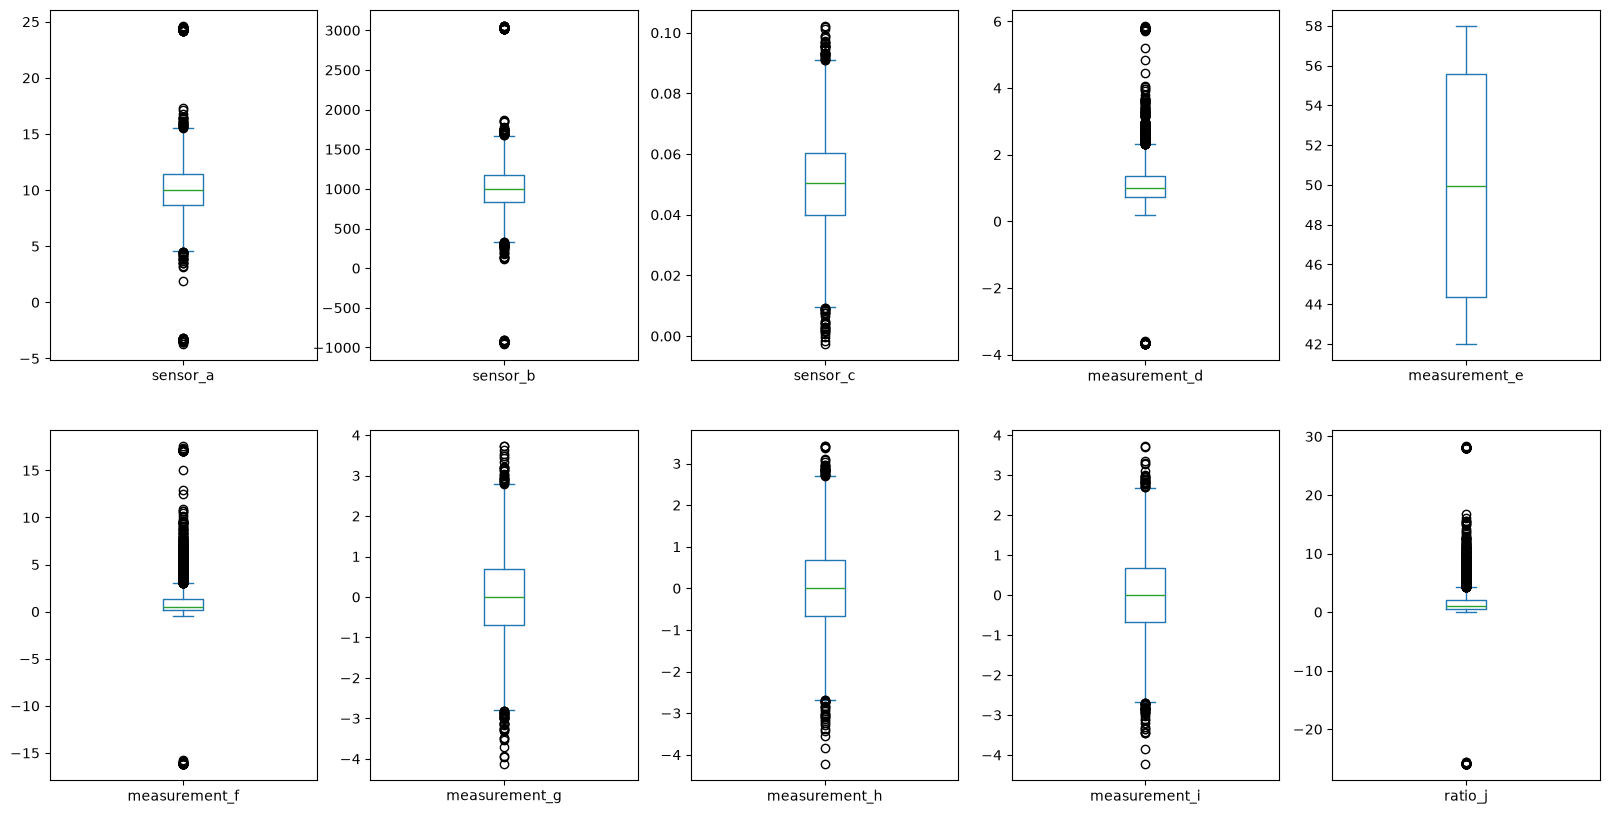

In [38]:
# boxplots
crop = df.drop(['target', 'encoded_environment'], axis=1)
crop.plot(kind='box', subplots=True, layout=(2, 5), figsize=(20, 10), sharey=False)

## Etapa 2.3: Análise de variáveis com correlação positiva através da Matriz de Correlação

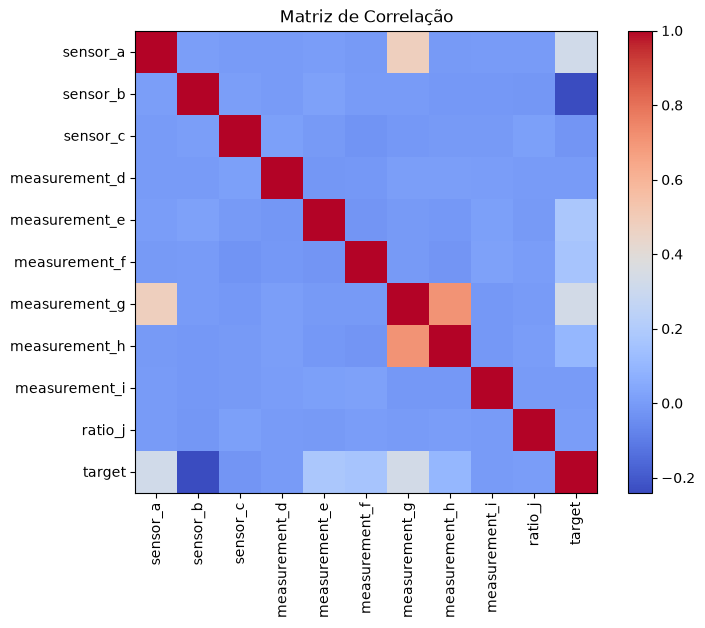

In [40]:
# # Matriz de correlação linear (Pearson)
corr_matrix_crop = df.drop(["sample_id", "encoded_environment", 'environment'], axis=1)
corr_matrix = corr_matrix_crop.corr()

# # Visualização simples da matriz
plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, cmap='coolwarm', interpolation='none')
plt.colorbar()
plt.xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix)), corr_matrix.columns)
plt.title("Matriz de Correlação")
plt.show()

## Interpretação dos dados:

- **As variáveis mais preditivas**: O ``sensor_b`` é a feature com maior correlação linear (negativa, tom azul escuro) com a variável ``target``. O ``sensor_a`` e a ``measurement_e`` também mostram alguma correlação positiva (tons mais claros de azul/branco) com o ``target``.

- **Multicolinearidade**: Temos uma forte correlação positiva (tom salmão) entre ``measurement_g`` e ``measurement_h`` e uma correlação moderada entre ``sensor_a`` e ``measurement_g``.

## Etapa 2.4: análise de correlação entre variáveis através do gráfico de dispersão.

Como pudemos ver na matriz de correlação , algumas variáveis possuem correlação positiva (``measurement_g``/``measurement_h`` e ``sensor_a``/``measurement_g``). Podemos plotar o gráfico de dispersão destas variáveis para identificar o nível de correlação entre elas.

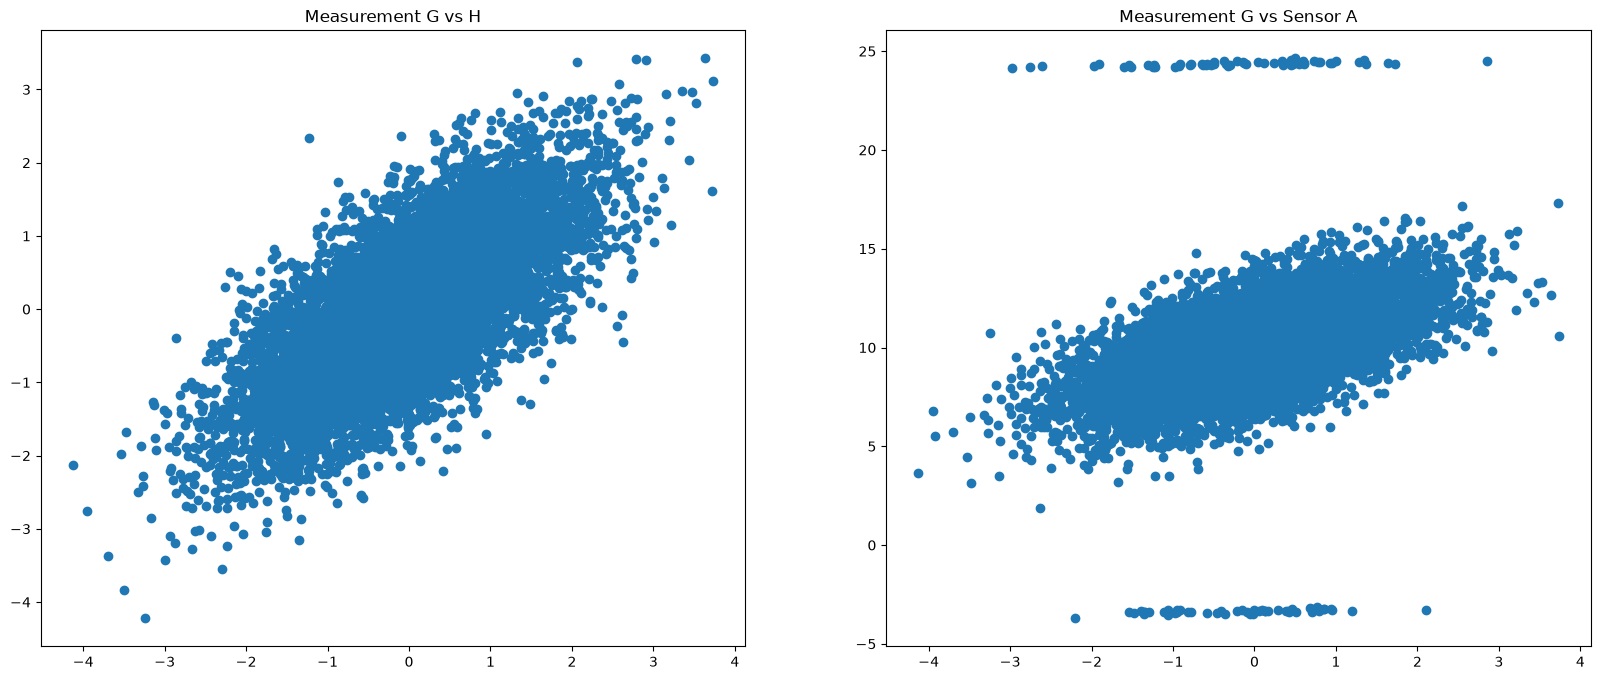

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))

axes[0].scatter(df['measurement_g'], df['measurement_h'])
axes[0].set_title('Measurement G vs H')

axes[1].scatter(df['measurement_g'], df['sensor_a'])
axes[1].set_title('Measurement G vs Sensor A')

plt.show()

## Interpretação dos gráficos:

- Embora a massa central de pontos mostre a correlação positiva moderada, a dispersão nos mostra um problema no sensor_a: existem duas linhas de valores extremos perfeitamente agrupadas na horizontal (uma no topo, perto de 24, e outra na base, perto de -4). Isso sugere que o sensor sofreu saturação física (atingiu o limite máximo/mínimo de medição) ou que ocorreu uma falha técnica na recolha dos dados.

# Etapa 5: Separação dos Dados

A Etapa 5 tem como objetivo separar o _dataset_ em dois ou mais conjuntos menores. Essa separação é feita para pode treinar o modelo com uma parte dos dados e depois alimentá-lo com dados que nunca foram vistos antes, com o fim de validar o modelo e como ele lida com informações novas.

## Estratégia de separação

Neste projeto será adotada a estratégia de **80% para treino** e **20% para teste**.

In [8]:
# separar features (X) e target (y)

X = df.drop(columns=['sample_id', 'target'])
y = df['target']

X_train, X_test, y_train, y_test = skl.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

# Observação
A etapa 5 foi executada agora, antes da Etapa 3, para evitar problemas com _data leakage_. Caso calculássemos os valores de imputação (método `fit`) sem antes separar o conjunto de dados, os dados de treino teriam informações que não deveriam a respeito do formato dos dados através das operações de imputação (média, mediana e moda). Sendo assim, separamos os dados antes e calculamos os valores apenas no conjunto de treino, aplicando a imputação no conjunto de testes sem fazer nenhum cálculo (método `transform`).

# Etapa 3: Tratamento de Dados Faltantes

A Etapa 3 tem como objetivo eliminar os valores ausentes (``NaN``) do dataset, pois as Redes Neurais (Keras/TensorFlow) e os algoritmos de escalonamento não conseguem processar entradas com dados faltantes.

In [9]:
sumario = pd.DataFrame({
    'Nulos': df.isnull().sum(),
    'Percentual (em %)': (df.isnull().sum() / len(df)) * 100
})

print(sumario[sumario['Nulos'] > 0])

                     Nulos  Percentual (em %)
sensor_a               414               4.14
sensor_b              1192              11.92
sensor_c               693               6.93
measurement_d          911               9.11
measurement_e          468               4.68
measurement_f         1011              10.11
measurement_g          603               6.03
measurement_h          855               8.55
measurement_i         1526              15.26
ratio_j               1061              10.61
environment            598               5.98
encoded_environment    598               5.98


Como podemos ver, todas as colunas possuem uma quantidade considerável de valores nulos, o que impossibilita a simples remoção de linhas nulas.
Conforme interpretação dos gráficos anteriores, as seguintes decisões serão tomadas:

- **Imputação por média**: dado o comportamento estatístico das variáveis ``sensor_c`` e ``measurement_i`` (seguem uma distribuição normal), os valores nulos nestas colunas serão substituídos pela média de suas respectivas colunas.

- **Imputação por mediana**: dado o comportamento estatístico das variáveis ``sensor_a``, ``sensor_b``, ``measurement_d``, ``measurement_f`` e ``ratio_j`` (presença severa de _outliers_, que distorcem o resultado de operações como a média), os valores nulos nestas colunas serão substituídos pela mediana de suas respectivas colunas, uma vez que a mediana é imune a distorção causada pelos _outliers_.

- **Imputação por moda**: a variável ``environment`` é uma variável categórica que, apesar de ter sido mapeada para valores numéricos, utilizar operações como média/moda/mediana pode distorcer o resultado que aparece na coluna após a imputação. Por conta disso, os valores nulos nesta coluna serão substituídos pela moda (valor que aparece com maior frequência) da coluna.

- **KNNImputer**: dada a correlação existente entre as variáveis ``measurement_g`` e ``measurement_h``, podemos tirar proveito da classe ``KNNImputer`` do ``scikit-learn``, que consegue preservar melhor a estrutura de correlação do que uma média simples.

In [41]:
# separar os conjuntos que serao utilizadas as operações de media/mediana/KNNImputer
cols_media = ['sensor_c', 'measurement_i']
cols_mediana = ['sensor_a', 'sensor_b', 'measurement_d', 'measurement_e', 'measurement_f', 'ratio_j']
cols_knn = ['measurement_g', 'measurement_h']

cat_pipeline = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
    ]
)

preprocessor = skl.compose.ColumnTransformer(
    transformers=[
        ('imp_media', SimpleImputer(strategy='mean'), cols_media),
        ('imp_mediana', SimpleImputer(strategy='median'), cols_mediana),
        ('imp_knn', KNNImputer(n_neighbors=5), cols_knn),
        ('cat', cat_pipeline, ['environment'])
    ],
    remainder=SimpleImputer(strategy='median')
)

# ajustar APENAS no treino e transformar treino e teste
X_train_imputed = preprocessor.fit_transform(X_train)
X_test_imputed = preprocessor.transform(X_test)


print("Formato de X_train_scaled:", X_train_scaled.shape)
print("Total de NaNs no treino:", np.isnan(X_train_scaled).sum())
print("Total de NaNs no teste:", np.isnan(X_test_scaled).sum())
print("Primeira linha transformada:\n", X_train_scaled[0])

colunas_usadas = set(cols_media + cols_mediana + cols_knn + ['environment'])
print("Colunas esquecidas:", set(X_train.columns) - colunas_usadas)

Formato de X_train_scaled: (8000, 14)
Total de NaNs no treino: 0
Total de NaNs no teste: 0
Primeira linha transformada:
 [ 1.14078116 -0.38309744  1.8129535   1.0044388  -0.50255378  0.54245387
 -7.8890015   0.04512928  0.17450473 -0.40451536 -0.67165136  1.4797948
 -0.77562981  1.26222891]
Colunas esquecidas: {'encoded_environment'}


# Etapa 4: Escalonamento dos Dados

Nesta etapa, os dados serão normalizados utilizando o `StandardScaler` do `scikit-learn`.

In [42]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Etapa 6

In [52]:
# cria o modelo ja aplicando regularizacao l2 nas camadas ocultas
model_reg = Sequential(
    [
        Input(shape=(X_train_scaled.shape[1],)), # camada de entrada
        
        Dense(16, activation='relu'), # primeira camada oculta
        
        Dense(8, activation='relu'), # segunda

        Dense(1, activation='sigmoid') # saida
    ]
)

model_reg.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_reg.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 16)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)

# Etapa 7/8

In [53]:
# configuracao do early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

history = model_reg.fit(
    X_train_scaled,
    y_train,
    batch_size=64,
    epochs=100,
    validation_split=0.2,
    verbose=0,
    callbacks=[early_stop]
)

Maior valor de acuracia:  0.8299999833106995
Maior valor de erro de validação:  0.592226505279541


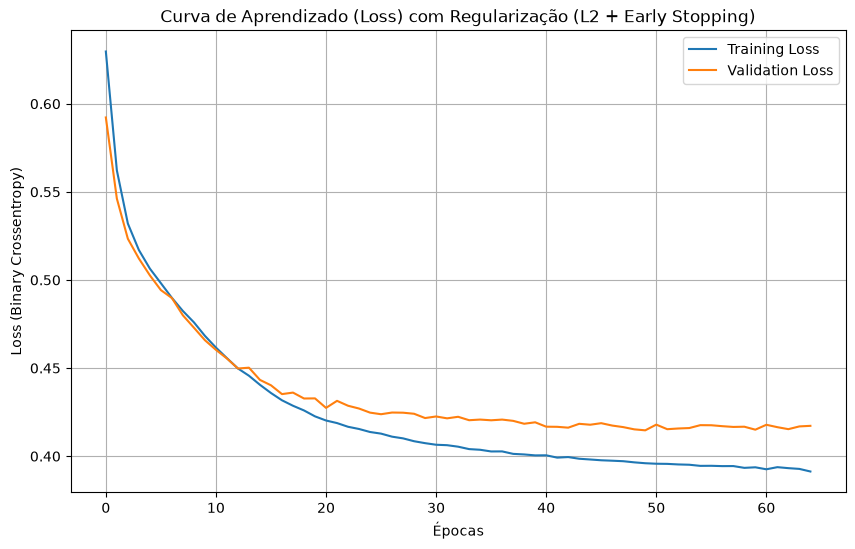

In [54]:
print(f"Maior valor de acuracia: ", max(history.history['accuracy']))
print(f"Maior valor de erro de validação: ", max(history.history['val_loss']))

    
plt.figure(figsize=(10, 6))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Curva de Aprendizado (Loss) com Regularização (L2 + Early Stopping)')
plt.xlabel('Épocas')
plt.ylabel('Loss (Binary Crossentropy)')
plt.legend()
plt.grid(True)
plt.show()

# Etapa 9

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
TP: 817 | TN: 795 | FP (Erro Tipo I): 196 | FN (Erro Tipo II): 192
-------------------------------------------------------
Accuracy (Acurácia):                 0.8060 (80.60%)
Sensitivity (Sensibilidade/Recall):  0.8097 (80.97%)
Specificity (Especificidade):        0.8022 (80.22%)
Precision (Precisão):                0.8065 (80.65%)
Negative Predictive Value (NPV):     0.8055 (80.55%)


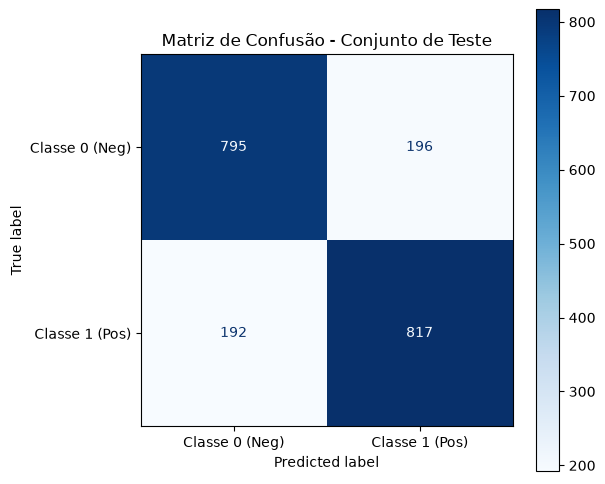

In [55]:
# gerar probabilidades e converter para classes binárias (limiar = 0.5)
y_pred_prob = model_reg.predict(X_test_scaled)
y_pred = (y_pred_prob >= 0.5).astype(int)

# calcular a Matriz de Confusão e extrair os quadrantes
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# alcular as 5 métricas do roteiro da disciplina
accuracy = (tp + tn) / (tp + tn + fp + fn)
sensitivity = tp / (tp + fn)  # Também chamada de Recall
specificity = tn / (tn + fp)
precision = tp / (tp + fp)
npv = tn / (tn + fn)          # Negative Predictive Value

print(f"TP: {tp} | TN: {tn} | FP (Erro Tipo I): {fp} | FN (Erro Tipo II): {fn}")
print("-" * 55)
print(f"Accuracy (Acurácia):                 {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Sensitivity (Sensibilidade/Recall):  {sensitivity:.4f} ({sensitivity*100:.2f}%)")
print(f"Specificity (Especificidade):        {specificity:.4f} ({specificity*100:.2f}%)")
print(f"Precision (Precisão):                {precision:.4f} ({precision*100:.2f}%)")
print(f"Negative Predictive Value (NPV):     {npv:.4f} ({npv*100:.2f}%)")

# plotar a Matriz de Confusão 
fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Classe 0 (Neg)', 'Classe 1 (Pos)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusão - Conjunto de Teste')
plt.show()